 ## Import Necessary Librares

In [1717]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score,confusion_matrix,classification_report,accuracy_score
from sklearn.preprocessing import StandardScaler,MinMaxScaler,LabelEncoder,OneHotEncoder
from sklearn.decomposition import PCA

**loading Dataset**

In [1718]:
df=pd.read_csv("live_fb.csv")

**Data Cleaning And Exploration**

In [1719]:
df.head()

,status_type,status_day,status_month,status_year,status_time,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,video,22,4,2018,06:00:00,529,512,262,432,92,3,1,1,0
1,photo,21,4,2018,22:45:00,150,0,0,150,0,0,0,0,0
2,video,21,4,2018,06:17:00,227,236,57,204,21,1,1,0,0
3,photo,21,4,2018,02:29:00,111,0,0,111,0,0,0,0,0
4,photo,18,4,2018,03:22:00,213,0,0,204,9,0,0,0,0


In [1720]:
df.shape

(7050, 14)

In [1721]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   status_type    7050 non-null   object
 1   status_day     7050 non-null   int64 
 2   status_month   7050 non-null   int64 
 3   status_year    7050 non-null   int64 
 4   status_time    7050 non-null   object
 5   num_reactions  7050 non-null   int64 
 6   num_comments   7050 non-null   int64 
 7   num_shares     7050 non-null   int64 
 8   num_likes      7050 non-null   int64 
 9   num_loves      7050 non-null   int64 
 10  num_wows       7050 non-null   int64 
 11  num_hahas      7050 non-null   int64 
 12  num_sads       7050 non-null   int64 
 13  num_angrys     7050 non-null   int64 
dtypes: int64(12), object(2)
memory usage: 771.2+ KB


In [1722]:
df.describe()

,status_day,status_month,status_year,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000
mean,15.792624,6.577730,2016.382128,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191
std,8.728489,3.587108,1.943176,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812
min,1.000000,1.000000,2012.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.000000,3.000000,2016.000000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,16.000000,6.000000,2017.000000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,23.000000,10.000000,2018.000000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000
max,31.000000,12.000000,2018.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000


In [1723]:
df.duplicated().sum()

np.int64(54)

In [1724]:
df.isnull().sum()

status_type      0
status_day       0
status_month     0
status_year      0
status_time      0
num_reactions    0
num_comments     0
num_shares       0
num_likes        0
num_loves        0
num_wows         0
num_hahas        0
num_sads         0
num_angrys       0
dtype: int64

In [1725]:
df=df.drop_duplicates()

In [1726]:
df.drop(["status_day","status_month","status_year","status_time"],axis=1,inplace=True)

In [1727]:
df["status_type"].unique()

array(['video', 'photo', 'link', 'status'], dtype=object)

**EDA (Exploratory Data Analysis)**

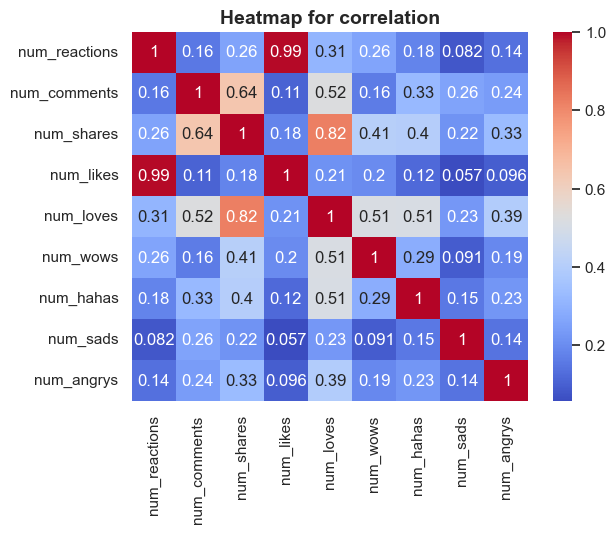

In [1728]:
numerical_data=df.select_dtypes(include=["int64","float64"])
corr=numerical_data.corr()
plt.Figure(figsize=(8,5))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Heatmap for correlation",fontsize=14,fontweight="bold")
plt.show()

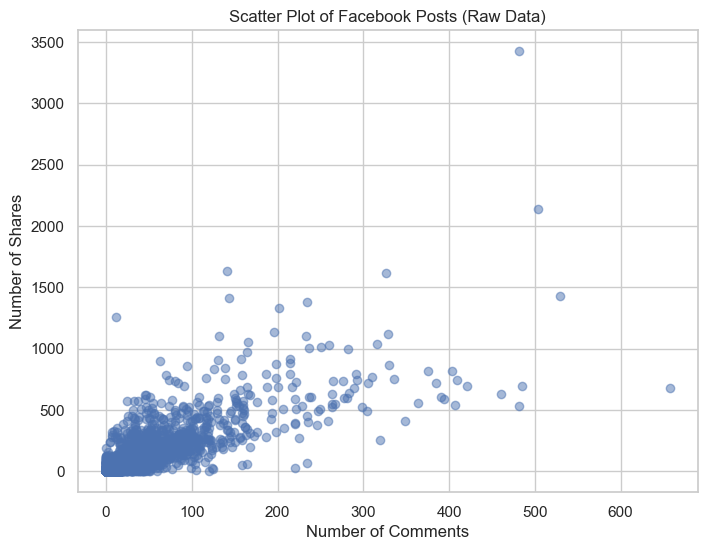

In [1729]:
plt.figure(figsize=(8,6))
plt.scatter(df["num_loves"], df["num_shares"], alpha=0.5)
plt.xlabel('Number of Comments')
plt.ylabel('Number of Shares')
plt.title('Scatter Plot of Facebook Posts (Raw Data)')
plt.show()

**Data Preprocessing**

In [1730]:
label_encoder=LabelEncoder()
df["status_type"]=label_encoder.fit_transform(df["status_type"])
df.head()


,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,3,529,512,262,432,92,3,1,1,0
1,1,150,0,0,150,0,0,0,0,0
2,3,227,236,57,204,21,1,1,0,0
3,1,111,0,0,111,0,0,0,0,0
4,1,213,0,0,204,9,0,0,0,0


In [1731]:
cols=df.columns
scaler=MinMaxScaler()
df=scaler.fit_transform(df)
df_scaled=pd.DataFrame(df,columns=cols)

df_scaled    

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,1.000000,0.112314,0.024393,0.076519,0.091720,0.140030,0.010791,0.006369,0.019608,0.0
1,0.333333,0.031847,0.000000,0.000000,0.031847,0.000000,0.000000,0.000000,0.000000,0.0
2,1.000000,0.048195,0.011243,0.016647,0.043312,0.031963,0.003597,0.006369,0.000000,0.0
3,0.333333,0.023567,0.000000,0.000000,0.023567,0.000000,0.000000,0.000000,0.000000,0.0
4,0.333333,0.045223,0.000000,0.000000,0.043312,0.013699,0.000000,0.000000,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...
6991,0.333333,0.018896,0.000000,0.000000,0.018896,0.000000,0.000000,0.000000,0.000000,0.0
6992,0.333333,0.003397,0.000000,0.000000,0.002972,0.001522,0.000000,0.006369,0.000000,0.0
6993,0.333333,0.000425,0.000000,0.000000,0.000212,0.001522,0.000000,0.000000,0.000000,0.0
6994,0.333333,0.074522,0.000572,0.006425,0.074098,0.003044,0.000000,0.000000,0.000000,0.0


****K_Means Model****

**Using Elbow Method To get Optimal K**

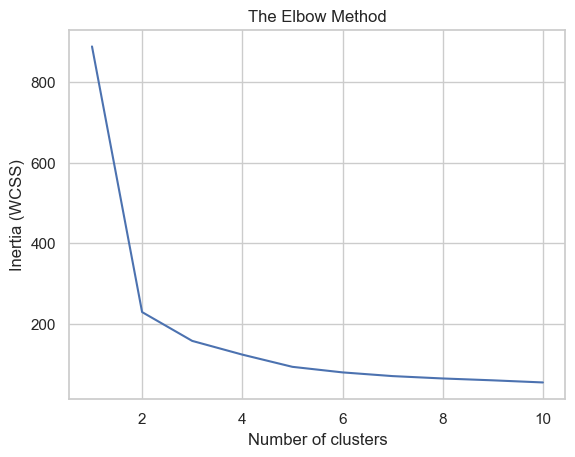

In [1732]:
wcss=[] # Within Cluster Sum Square

for i in range(1,11): 
  kmeans=KMeans(n_clusters=i,init='k-means++',n_init=10,max_iter=300,random_state=42)
  kmeans.fit(df_scaled)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia (WCSS)')
plt.show()


k=2, silhouette score=0.768
k=3, silhouette score=0.787
k=4, silhouette score=0.779
k=5, silhouette score=0.770
k=6, silhouette score=0.773
k=7, silhouette score=0.723
k=8, silhouette score=0.712
k=9, silhouette score=0.720
k=10, silhouette score=0.711


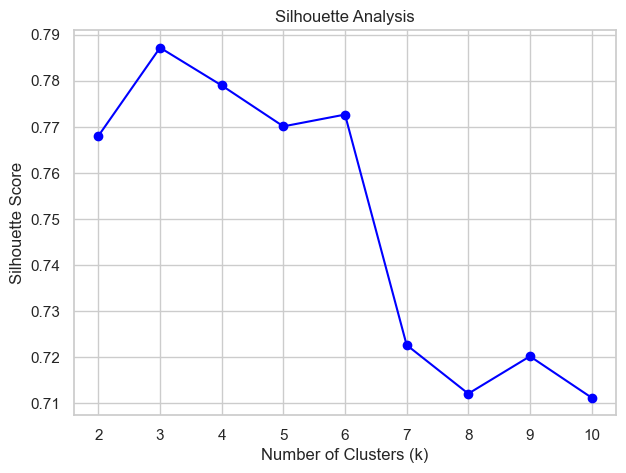

In [1733]:
# select optimal k from 2 to 10 depend of high silhouette score 
sil_scores = {}
for i in range(2, 11):  
    kmeans=KMeans(n_clusters=i,init='k-means++',n_init=10,max_iter=300,random_state=42)
    labels = kmeans.fit_predict(df_scaled)
    sil = silhouette_score(df_scaled, labels)
    sil_scores[i] = sil
    print(f"k={i}, silhouette score={sil:.3f}")

plt.figure(figsize=(7,5))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), 'o-', color='blue')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()

**best k is 3**

In [1734]:
kmeans=KMeans(n_clusters=3,init="k-means++",n_init=10,max_iter=300,random_state=42)
kmeans.fit(df_scaled)


,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [1735]:
labels = kmeans.fit_predict(df_scaled)
sil = silhouette_score(df_scaled, labels)
print(f"silhoutte score:{sil:.3f}")

silhoutte score:0.787


**Visualization with PCA **

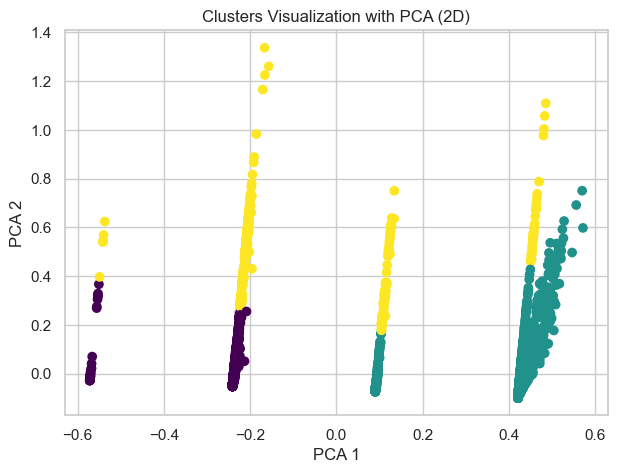

In [1736]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(df_scaled)
plt.figure(figsize=(7,5))
plt.scatter(x_pca[:,0], x_pca[:,1], c=kmeans.labels_, cmap="viridis")
plt.title("Clusters Visualization with PCA (2D)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

**Add Clusters to Dataset**

In [1737]:
df_scaled['Cluster'] = labels
df_scaled.head()

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Cluster
0,1.000000,0.112314,0.024393,0.076519,0.091720,0.140030,0.010791,0.006369,0.019608,0.0,1
1,0.333333,0.031847,0.000000,0.000000,0.031847,0.000000,0.000000,0.000000,0.000000,0.0,0
2,1.000000,0.048195,0.011243,0.016647,0.043312,0.031963,0.003597,0.006369,0.000000,0.0,1
3,0.333333,0.023567,0.000000,0.000000,0.023567,0.000000,0.000000,0.000000,0.000000,0.0,0
4,0.333333,0.045223,0.000000,0.000000,0.043312,0.013699,0.000000,0.000000,0.000000,0.0,0


**Using Supervised Classification Model**

**selecting random forest model and training**

In [1738]:
x=df_scaled.drop('Cluster',axis=1) #Features
y=df_scaled['Cluster'] #Target

In [1739]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42) #80% training , 20% test

In [1740]:
rf_model=RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**model prediction and evaluation**

In [1741]:
y_pred=rf_model.predict(x_test)

In [1742]:
acc=accuracy_score(y_test,y_pred)
print("Accuracy=",acc)

Accuracy= 0.9992857142857143


In [1743]:
#confusion matrix
cm=confusion_matrix(y_test,y_pred)
print("confusion matrix=",cm)

confusion matrix= [[837   0   1]
 [  0 506   0]
 [  0   0  56]]


In [1744]:
cr=classification_report(y_test,y_pred)
print("classification report=",cr)

classification report=               precision    recall  f1-score   support

           0       1.00      1.00      1.00       838
           1       1.00      1.00      1.00       506
           2       0.98      1.00      0.99        56

    accuracy                           1.00      1400
   macro avg       0.99      1.00      1.00      1400
weighted avg       1.00      1.00      1.00      1400



**save model**

In [1745]:
import pickle

with open("randomforest_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)


In [1746]:
import joblib
joblib.dump(scaler, "scaler.joblib")
print(" Scaler saved successfully")


 Scaler saved successfully


In [1747]:
import joblib

# Save everything into one file
joblib.dump(
    {"model": rf_model, "scaler": scaler, "encoder": label_encoder},
    "rf_with_scaler_encoder.pkl"
)

print("✅ Model + Scaler + Encoder saved successfully in rf_with_scaler_encoder.pkl")

✅ Model + Scaler + Encoder saved successfully in rf_with_scaler_encoder.pkl
